# Etapa 2 – Preparação e integração dos dados

Carga máxima diária do subsistema Sul, de 2015 a 2025.

Entradas:
- dados brutos do ONS em `dataset/`, gerados por `download_ons.py`;
- clima do Open-Meteo deixado em `dataset/clima_open_meteo/`;
- feriados da biblioteca `holidays`.

Saídas em `processado/`:
- `base_horaria.parquet`, `base_diaria.parquet`, `base_semanal.parquet`, `base_mensal.parquet`;
- `benchmark_ons.parquet`.

## 1. Configuração

In [1]:
from pathlib import Path
import json
import time

import holidays
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import requests

pd.set_option("display.max_columns", 50)
plt.rcParams["figure.figsize"] = (12, 4)

DIR_RAW = Path("dataset")
DIR_CLIMA = DIR_RAW / "clima_open_meteo"
DIR_OUT = Path("processado")

INICIO, FIM = "2015-01-01", "2025-12-31"
SUBSISTEMA = "S"
FUSO = "America/Sao_Paulo"  # o ONS registra a hora local (com horário de verão)

# População residente, IBGE – Censo Demográfico 2022
POPULACAO = {"PR": 11_444_380, "SC": 7_610_361, "RS": 10_882_965}
PESO = {uf: p / sum(POPULACAO.values()) for uf, p in POPULACAO.items()}

# Capital de cada estado, representando o clima do estado
CIDADES = {
    "curitiba":      {"uf": "PR", "lat": -25.4284, "lon": -49.2733},
    "florianopolis": {"uf": "SC", "lat": -27.5954, "lon": -48.5480},
    "porto_alegre":  {"uf": "RS", "lat": -30.0346, "lon": -51.2177},
}
VARS_CLIMA = ["temperature_2m", "apparent_temperature", "relative_humidity_2m", "precipitation"]

# Limiares dos graus-dia (°C), usados em H1 (calor) e H3 (frio)
T_BASE_CALOR, T_BASE_FRIO = 24.0, 18.0

# Limpeza da série horária
MAX_LACUNA_INTERPOLADA = 3   # horas
Z_SUSPEITO = 6.0         

# Mudanças de metodologia da carga do ONS (descrição do dataset Carga de Energia Diária)
REGIMES_ONS = [("2021-03-01", 1), ("2023-04-29", 2)]  # 0 antes de 01/03/2021; 2 = inclui MMGD estimada
PANDEMIA = ("2020-03-16", "2020-12-31")

PESO

{'PR': 0.3822731107052758, 'SC': 0.2542065514304937, 'RS': 0.3635203378642305}

## 2. Leitura da Curva de Carga Horária (ONS)

Os valores vêm como texto. Strings vazias são convertidas para NaN. Em alguns arquivos, `id_subsistema` tem espaços no fim (`'S  '`), por isso o filtro usa `strip()`.

In [2]:
if not (DIR_RAW / "curva_carga_horaria").exists():
    raise FileNotFoundError("Rode antes: python3 download_ons.py dataset/")

def ler_ons(pasta, col_valor, col_data="din_instante"):
    df = pd.concat(pd.read_parquet(f) for f in sorted((DIR_RAW / pasta).glob("*.parquet")))
    df = df[df["id_subsistema"].str.strip() == SUBSISTEMA].copy()
    df[col_valor] = pd.to_numeric(df[col_valor].replace("", np.nan), errors="coerce")
    return df.sort_values(col_data).reset_index(drop=True)

ons = ler_ons("curva_carga_horaria", "val_cargaenergiahomwmed")
ons = ons[(ons.din_instante >= INICIO) & (ons.din_instante < pd.Timestamp(FIM) + pd.Timedelta(days=1))]
print(ons.shape, ons.din_instante.min(), ons.din_instante.max())
ons.head()

(96432, 4) 2015-01-01 00:00:00 2025-12-31 23:00:00


,id_subsistema,nom_subsistema,din_instante,val_cargaenergiahomwmed
0,S,SUL,2015-01-01 00:00:00,8054.928873
1,S,SUL,2015-01-01 01:00:00,8149.414164
2,S,SUL,2015-01-01 02:00:00,7914.000143
3,S,SUL,2015-01-01 03:00:00,7608.088772
4,S,SUL,2015-01-01 04:00:00,7328.819462


## 3. Relógio do ONS: hora local ou relógio fixo?

O Brasil teve horário de verão até fev/2019. Se o ONS registrasse num relógio fixo (UTC−3), o perfil diário de carga se deslocaria 1 hora a cada troca de horário, porque o consumo segue a hora local.

O teste compara o perfil médio dos dias úteis nas duas semanas antes e nas duas semanas depois de cada troca. Ele procura o deslocamento (−1, 0 ou +1 hora) que melhor alinha os dois perfis.

In [3]:
TROCAS_DST = ["2015-10-18", "2016-02-21", "2016-10-16", "2017-02-19", "2017-10-15",
              "2018-02-18", "2018-11-04", "2019-02-17"]
serie = ons.set_index("din_instante")["val_cargaenergiahomwmed"]

def perfil(a, b):
    x = serie[a:b]
    x = x[x.index.day_of_week < 5]
    p = x.groupby(x.index.hour).mean()
    return p / p.max()

linhas = []
for t in TROCAS_DST:
    T = pd.Timestamp(t)
    antes = perfil(T - pd.Timedelta(days=14), T - pd.Timedelta(hours=1))
    depois = perfil(T + pd.Timedelta(days=1), T + pd.Timedelta(days=15))
    erro = {k: float(((depois.values - antes.shift(-k).values) ** 2)[2:20].sum()) for k in (-1, 0, 1)}
    linhas.append({"troca": t, **{f"erro_desloc_{k:+d}h": round(v, 4) for k, v in erro.items()},
                   "melhor_deslocamento_h": min(erro, key=erro.get)})
pd.DataFrame(linhas)

,troca,erro_desloc_-1h,erro_desloc_+0h,erro_desloc_+1h,melhor_deslocamento_h
0,2015-10-18,0.0472,0.0118,0.0466,0
1,2016-02-21,0.0706,0.0193,0.0403,0
2,2016-10-16,0.0492,0.0190,0.0480,0
3,2017-02-19,0.0482,0.0099,0.0383,0
4,2017-10-15,0.0435,0.0100,0.0402,0
5,2018-02-18,0.0495,0.0123,0.0398,0
6,2018-11-04,0.0332,0.0250,0.0669,0
7,2019-02-17,0.0425,0.0134,0.0516,0


In [4]:
# Horas registradas em torno do início de um horário de verão (00:00 não existe na hora local)
serie["2018-11-03 22:00":"2018-11-04 02:00"]

din_instante
2018-11-03 22:00:00    9394.599012
2018-11-03 23:00:00    8630.810012
2018-11-04 00:00:00       0.000000
2018-11-04 01:00:00    7879.505003
2018-11-04 02:00:00    7356.702000
Name: val_cargaenergiahomwmed, dtype: float64

**Resultado:** em todas as trocas o melhor deslocamento é 0 hora. Além disso, a hora 00:00 dos dias de início do horário de verão, que não existe na hora local, vem vazia ou zerada.

O ONS registra a **hora local de Brasília (`America/Sao_Paulo`)**, então o clima é convertido para esse mesmo fuso antes da junção. Nos dias de início do horário de verão, a hora 00:00 é tratada como inexistente: o dia tem 23 horas reais e essa hora não é imputada.

> **Interpretação**
>
> Nas 8 trocas de horário de verão entre 2015 e 2019, o perfil de carga não muda de lugar: o menor erro é sempre com deslocamento 0. O consumo acompanha o relógio das pessoas, e o ONS registra nesse mesmo relógio. Por isso o clima (baixado em UTC) foi convertido para o horário de Brasília antes de juntar as duas fontes. Sem isso, as temperaturas ficariam 1 hora fora do lugar nos verões até 2019.

## 4. Qualidade da série horária

| Problema | Tratamento | Coluna |
|---|---|---|
| Instante duplicado | Valores iguais: mantém um. Valores divergentes: média. | `duplicado` |
| Hora faltante na grade 2015–2025 | Reindexação | – |
| Hora inexistente (início do horário de verão) | Fica NaN e não é imputada | `hora_inexistente_dst` |
| Valor vazio, zero ou negativo | Vira NaN | `invalido` |
| Variação hora a hora extrema (z robusto > `Z_SUSPEITO`) | **Fica na base**; só recebe a flag | `suspeito` |
| Lacuna de até `MAX_LACUNA_INTERPOLADA` horas | Interpolação linear | `imputado` |
| Lacuna maior | Fica NaN | – |

In [5]:
h = ons[["din_instante", "val_cargaenergiahomwmed"]].rename(
    columns={"din_instante": "instante", "val_cargaenergiahomwmed": "carga_bruta"})

# Duplicados
dup = h.duplicated("instante", keep=False)
print("instantes duplicados:", h.loc[dup, "instante"].nunique())
h = h.groupby("instante", as_index=False).agg(carga_bruta=("carga_bruta", "mean"),
                                              n_registros=("carga_bruta", "size"))
h["duplicado"] = h["n_registros"] > 1

# Grade horária completa
grade = pd.date_range(INICIO, f"{FIM} 23:00", freq="h", name="instante")
h = h.set_index("instante").reindex(grade).reset_index()
h["faltante"] = h["carga_bruta"].isna() & h["n_registros"].isna()
print("horas na grade:", len(grade), "| horas ausentes do arquivo:", int(h["faltante"].sum()))

# Horas que não existem na hora local (início do horário de verão)
def hora_inexistente(ts):
    loc = ts.dt.tz_localize(FUSO, nonexistent="NaT", ambiguous=False)
    return loc.isna()

h["hora_inexistente_dst"] = hora_inexistente(h["instante"])

# Valores inválidos
h["invalido"] = (h["carga_bruta"].isna() | (h["carga_bruta"] <= 0)) & ~h["hora_inexistente_dst"]
h["carga"] = h["carga_bruta"].where(h["carga_bruta"] > 0)
h.loc[h["hora_inexistente_dst"], "carga"] = np.nan

# Saltos suspeitos (flag apenas)
d = h["carga"].diff()
mad = (d - d.median()).abs().median()
z = (d - d.median()).abs() / (1.4826 * mad)
h["suspeito"] = (z > Z_SUSPEITO).fillna(False)

# Interpolação só de lacunas curtas (sem tocar nas horas inexistentes)
falta = h["carga"].isna() & ~h["hora_inexistente_dst"]
bloco = (falta != falta.shift()).cumsum()
tam_lacuna = falta.groupby(bloco).transform("sum")
interpolavel = falta & (tam_lacuna <= MAX_LACUNA_INTERPOLADA)
base_interp = h["carga"].where(~h["hora_inexistente_dst"])
interp_vals = base_interp.interpolate(limit_area="inside")
h["imputado"] = interpolavel & interp_vals.notna()
h.loc[h["imputado"], "carga"] = interp_vals[h["imputado"]]

h = h.drop(columns=["n_registros"])
h.head()

instantes duplicados: 0
horas na grade: 96432 | horas ausentes do arquivo: 0


,instante,carga_bruta,duplicado,faltante,hora_inexistente_dst,invalido,carga,suspeito,imputado
0,2015-01-01 00:00:00,8054.928873,False,False,False,False,8054.928873,False,False
1,2015-01-01 01:00:00,8149.414164,False,False,False,False,8149.414164,False,False
2,2015-01-01 02:00:00,7914.000143,False,False,False,False,7914.000143,False,False
3,2015-01-01 03:00:00,7608.088772,False,False,False,False,7608.088772,False,False
4,2015-01-01 04:00:00,7328.819462,False,False,False,False,7328.819462,False,False


In [6]:
qualidade = (h.assign(ano=h["instante"].dt.year)
               .groupby("ano")[["duplicado", "faltante", "hora_inexistente_dst", "invalido", "suspeito", "imputado"]]
               .sum())
qualidade["nan_restante"] = (h.assign(ano=h["instante"].dt.year)
                               .pipe(lambda x: x[x["carga"].isna() & ~x["hora_inexistente_dst"]])
                               .groupby("ano").size())
qualidade = qualidade.fillna(0).astype(int)
qualidade

,duplicado,faltante,hora_inexistente_dst,invalido,suspeito,imputado,nan_restante
ano,,,,,,,
2015,0,0,1,24,0,0,24
2016,0,0,1,0,0,0,0
2017,0,0,1,0,0,0,0
2018,0,0,1,0,0,0,0
2019,0,0,0,0,0,0,0
2020,0,0,0,0,0,0,0
2021,0,0,0,0,0,0,0
2022,0,0,0,0,0,0,0
2023,0,0,0,0,0,0,0


In [7]:
# Datas com valores inválidos ou suspeitos
h.loc[h["invalido"] | h["suspeito"], ["instante", "carga_bruta", "carga", "invalido", "suspeito", "imputado"]]

,instante,carga_bruta,carga,invalido,suspeito,imputado
2352,2015-04-09 00:00:00,NaN,NaN,True,False,False
2353,2015-04-09 01:00:00,NaN,NaN,True,False,False
2354,2015-04-09 02:00:00,NaN,NaN,True,False,False
2355,2015-04-09 03:00:00,NaN,NaN,True,False,False
2356,2015-04-09 04:00:00,NaN,NaN,True,False,False
2357,2015-04-09 05:00:00,NaN,NaN,True,False,False
2358,2015-04-09 06:00:00,NaN,NaN,True,False,False
2359,2015-04-09 07:00:00,NaN,NaN,True,False,False
2360,2015-04-09 08:00:00,NaN,NaN,True,False,False
2361,2015-04-09 09:00:00,NaN,NaN,True,False,False


> **Interpretação**
>
> A série horária está praticamente completa. Não há horários repetidos nem faltando, nenhuma variação brusca foi marcada como suspeita e nada precisou ser interpolado. O único problema real é o dia **09/04/2015**, que veio inteiro vazio no arquivo do ONS. Ele ficou sem valor (`dia_incompleto = True`), porque inventar 24 horas seguidas não seria confiável. As 4 horas marcadas em `hora_inexistente_dst` (meia-noite dos dias de início do horário de verão, 2015–2018) não existiram no relógio local e por isso também não foram preenchidas.

## 5. Clima – Open-Meteo (API histórica)

- Uma chamada por cidade, com o período inteiro mais um dia em cada ponta, em `timezone=GMT`. A resposta bruta fica em `dataset/clima_open_meteo/<cidade>.csv` e é reutilizada se já existir.
- Os instantes são convertidos para `America/Sao_Paulo`, o mesmo relógio do ONS. Na hora repetida do fim do horário de verão, usa-se a média.
- Por cidade e por dia: Tmax, Tmin e Tmédia, Tmax aparente, umidade média e chuva total.
- Valor do Sul: média ponderada pela população de cada estado (Censo 2022).

In [8]:
URL_ARCHIVE = "https://archive-api.open-meteo.com/v1/archive"

def baixar_clima(nome, cfg, tentativas=4):
    caminho = DIR_CLIMA / f"{nome}.csv"
    if caminho.exists():
        return pd.read_csv(caminho, parse_dates=["time"])
    DIR_CLIMA.mkdir(parents=True, exist_ok=True)
    # um dia a mais em cada ponta: o período em UTC precisa cobrir o período inteiro na hora local
    ini = (pd.Timestamp(INICIO) - pd.Timedelta(days=1)).date().isoformat()
    fim = (pd.Timestamp(FIM) + pd.Timedelta(days=1)).date().isoformat()
    params = {"latitude": cfg["lat"], "longitude": cfg["lon"], "start_date": ini, "end_date": fim,
              "hourly": ",".join(VARS_CLIMA), "timezone": "GMT"}
    for i in range(tentativas):
        try:
            r = requests.get(URL_ARCHIVE, params=params, timeout=300)
            r.raise_for_status()
            break
        except requests.RequestException:
            if i == tentativas - 1:
                raise
            time.sleep(10 * 2 ** i)
    df = pd.DataFrame(r.json()["hourly"])
    df["time"] = pd.to_datetime(df["time"])
    df.to_csv(caminho, index=False)
    return df

clima_bruto = {}
for nome, cfg in CIDADES.items():
    clima_bruto[nome] = baixar_clima(nome, cfg)
    print(nome, clima_bruto[nome].shape, clima_bruto[nome]["time"].min(), clima_bruto[nome]["time"].max())

curitiba (96480, 5) 2014-12-31 00:00:00 2026-01-01 23:00:00
florianopolis (96480, 5) 2014-12-31 00:00:00 2026-01-01 23:00:00
porto_alegre (96480, 5) 2014-12-31 00:00:00 2026-01-01 23:00:00


In [9]:
def para_hora_local(df):
    """UTC -> hora local de Brasília sem fuso, igual ao ONS; média na hora repetida."""
    out = df.copy()
    out["instante"] = (out["time"].dt.tz_localize("UTC").dt.tz_convert(FUSO).dt.tz_localize(None))
    out = out.drop(columns="time").groupby("instante").mean()
    return out.loc[INICIO:f"{FIM} 23:00"]

clima_h = {nome: para_hora_local(df) for nome, df in clima_bruto.items()}
print({nome: (len(df), int(df.isna().sum().sum())) for nome, df in clima_h.items()})

{'curitiba': (96428, 0), 'florianopolis': (96428, 0), 'porto_alegre': (96428, 0)}


In [10]:
def clima_diario(df):
    g = df.groupby(df.index.normalize())
    return pd.DataFrame({
        "tmax": g["temperature_2m"].max(),
        "tmin": g["temperature_2m"].min(),
        "tmed": g["temperature_2m"].mean(),
        "tmax_aparente": g["apparent_temperature"].max(),
        "umidade_med": g["relative_humidity_2m"].mean(),
        "chuva_mm": g["precipitation"].sum(),
    })

def ponderar(tabelas):
    """Média do Sul ponderada pela população do estado de cada cidade."""
    return sum(tab * PESO[CIDADES[nome]["uf"]] for nome, tab in tabelas.items())

clima_d_cidade = {nome: clima_diario(df) for nome, df in clima_h.items()}
clima_d = ponderar(clima_d_cidade)
clima_d["cdd"] = (clima_d["tmed"] - T_BASE_CALOR).clip(lower=0)
clima_d["hdd"] = (T_BASE_FRIO - clima_d["tmed"]).clip(lower=0)
# Tmax de cada capital, para análises por estado
for nome, tab in clima_d_cidade.items():
    clima_d[f"tmax_{nome}"] = tab["tmax"]
clima_d.index.name = "data"

clima_hora = ponderar({n: df[["temperature_2m", "relative_humidity_2m", "precipitation"]] for n, df in clima_h.items()})
clima_hora.columns = ["temperatura", "umidade", "chuva_mm"]
clima_d.describe().round(1)

,tmax,tmin,tmed,tmax_aparente,umidade_med,chuva_mm,cdd,hdd,tmax_curitiba,tmax_florianopolis,tmax_porto_alegre
count,4018.0,4018.0,4018.0,4018.0,4018.0,4018.0,4018.0,4018.0,4018.0,4018.0,4018.0
mean,23.7,15.8,19.3,25.0,81.3,4.1,0.1,1.1,22.3,24.4,24.7
std,4.2,4.0,3.9,6.0,5.2,5.9,0.4,2.0,4.3,4.0,5.5
min,10.4,1.4,6.4,5.5,51.2,0.0,0.0,0.0,7.0,12.8,9.2
25%,20.8,13.0,16.6,20.8,78.1,0.2,0.0,0.0,19.5,21.5,20.8
50%,24.0,16.2,19.6,25.2,81.8,1.6,0.0,0.0,22.7,24.4,25.1
75%,26.8,18.9,22.3,29.6,84.8,5.8,0.0,1.4,25.5,27.2,28.8
max,33.9,23.8,28.3,39.8,94.7,49.9,4.3,11.6,34.6,38.1,39.0


> **Interpretação**
>
> As três capitais têm dados completos para os 4.018 dias. No Sul, a temperatura máxima diária fica em média em 23,7 °C, indo de 10,4 °C a 33,9 °C. Porto Alegre é a capital com maior variação (verões mais quentes e invernos mais frios) e Curitiba é a mais fria. Como a média é ponderada pela população, as temperaturas extremas de uma cidade isolada ficam suavizadas: Porto Alegre chegou a 39 °C, mas o máximo do Sul foi 33,9 °C.
>
> Os indicadores de calor e frio são desiguais. A média diária passa de 24 °C em só cerca de 11% dos dias, então `cdd` quase sempre vale zero. Já `hdd` (média abaixo de 18 °C) é positivo em cerca de 36% dos dias. Para estudar o efeito do calor (H1), a temperatura máxima tende a ser mais útil que o `cdd`.

## 6. Feriados – biblioteca `holidays`

- Feriados nacionais e os estaduais de PR, SC e RS, de 2015 a 2025.
- **Carnaval (segunda e terça) e Corpus Christi** são opcionais na biblioteca, mas entram como `feriado_nacional`. A Quarta-feira de Cinzas, o Dia do Servidor e as vésperas de Natal e Ano Novo não entram.
- `frac_pop_feriado_estadual` é a fração da população do Sul em feriado estadual naquele dia.
- `ponte` marca a segunda-feira antes de um feriado na terça e a sexta-feira depois de um feriado na quinta.

In [11]:
ANOS = range(pd.Timestamp(INICIO).year, pd.Timestamp(FIM).year + 1)
# um ano a mais em cada ponta, para véspera/dia seguinte nas bordas do período
ANOS_EXT = range(ANOS.start - 1, ANOS.stop + 1)
OPCIONAIS_INCLUIDOS = ("Carnaval", "Corpus Christi")

nac = holidays.Brazil(years=ANOS_EXT, language="pt_BR")
opc = holidays.Brazil(years=ANOS_EXT, language="pt_BR", categories=("optional",))
feriados_nac = dict(nac)
feriados_nac.update({d: n for d, n in opc.items() if n.startswith(OPCIONAIS_INCLUIDOS)})

estaduais = {}
for uf in POPULACAO:
    est = holidays.Brazil(years=ANOS, subdiv=uf, language="pt_BR")
    estaduais[uf] = {d: n for d, n in est.items() if d not in nac}

dias = pd.date_range(INICIO, FIM, freq="D", name="data")
fer = pd.DataFrame(index=dias)
fer["feriado_nacional"] = [d.date() in feriados_nac for d in dias]
fer["frac_pop_feriado_estadual"] = [sum(PESO[uf] for uf in POPULACAO if d.date() in estaduais[uf]) for d in dias]
nomes = []
for d in dias:
    n = [feriados_nac[d.date()]] if d.date() in feriados_nac else []
    n += [f"{estaduais[uf][d.date()]} ({uf})" for uf in POPULACAO if d.date() in estaduais[uf]]
    nomes.append("; ".join(n) if n else None)
fer["nome_feriado"] = pd.array(nomes, dtype="string")
fer["feriado"] = fer["feriado_nacional"] | (fer["frac_pop_feriado_estadual"] > 0)

# Véspera, dia seguinte e ponte (em relação a feriados nacionais)
amanha = [(d + pd.Timedelta(days=1)).date() in feriados_nac for d in dias]
ontem = [(d - pd.Timedelta(days=1)).date() in feriados_nac for d in dias]
fer["vespera_feriado"] = np.array(amanha) & ~fer["feriado_nacional"].values
fer["pos_feriado"] = np.array(ontem) & ~fer["feriado_nacional"].values
dow = dias.day_of_week
fer["ponte"] = (((dow == 0) & np.array(amanha)) | ((dow == 4) & np.array(ontem))) & ~fer["feriado"].values

print(fer.groupby(fer.index.year)[["feriado_nacional", "feriado", "vespera_feriado", "pos_feriado", "ponte"]].sum())
fer[fer["feriado"]].loc["2024"]

      feriado_nacional  feriado  vespera_feriado  pos_feriado  ponte
data                                                                
2015                12       15               11           11      3
2016                12       15               11           11      3
2017                12       15               11           11      4
2018                12       15               11           11      5
2019                12       15               11           11      1
2020                12       15               11           11      2
2021                12       15               11           11      4
2022                12       15               11           11      3
2023                12       15               11           11      4
2024                13       16               12           12      1
2025                13       16               12           12      4


,feriado_nacional,frac_pop_feriado_estadual,nome_feriado,feriado,vespera_feriado,pos_feriado,ponte
data,,,,,,,
2024-01-01,True,0.000000,Confraternização Universal,True,False,False,False
2024-02-12,True,0.000000,Carnaval,True,False,False,False
2024-02-13,True,0.000000,Carnaval,True,False,False,False
2024-03-29,True,0.000000,Sexta-feira Santa,True,False,False,False
2024-04-21,True,0.000000,Tiradentes,True,False,False,False
2024-05-01,True,0.000000,Dia do Trabalhador,True,False,False,False
2024-05-30,True,0.000000,Corpus Christi,True,False,False,False
2024-08-11,False,0.254207,Dia do Estado de Santa Catarina (SC),True,False,False,False
2024-09-07,True,0.000000,Independência do Brasil,True,False,False,False


## 7. Calendário e regimes

In [12]:
cal = pd.DataFrame(index=dias)
cal["ano"] = dias.year
cal["mes"] = dias.month
cal["dia_semana"] = dias.day_of_week          # 0 = segunda
cal["fim_de_semana"] = cal["dia_semana"] >= 5
cal["dia_ano"] = dias.day_of_year
cal["semana_iso"] = dias.isocalendar().week.astype(int).values
cal["regime_ons"] = 0
for inicio_regime, codigo in REGIMES_ONS:
    cal.loc[cal.index >= inicio_regime, "regime_ons"] = codigo
cal["pandemia"] = (cal.index >= PANDEMIA[0]) & (cal.index <= PANDEMIA[1])
cal["regime_ons"].value_counts().sort_index()

regime_ons
0    2251
1     789
2     978
Name: count, dtype: int64

## 8. Agregações

- **Horária:** a carga limpa com as flags, mais o clima ponderado do Sul na mesma hora.
- **Diária:** `carga_max` (variável-alvo), `carga_media`, `carga_min`, `hora_pico`, `n_horas_obs`, `n_horas_imputadas` e `dia_incompleto` (menos horas válidas que as horas reais do dia). Junta-se clima, feriados e calendário pela data.
- **Semanal** (semana ISO, de segunda a domingo; chave = segunda-feira) e **mensal** (chave = 1º dia do mês): calculadas a partir da diária.

In [13]:
base_horaria = (h.set_index("instante")
                 .join(clima_hora)
                 .reset_index())
base_horaria["data"] = base_horaria["instante"].dt.normalize()

hd = base_horaria.groupby("data")
carga_d = pd.DataFrame({
    "carga_max": hd["carga"].max(),
    "carga_media": hd["carga"].mean(),
    "carga_min": hd["carga"].min(),
    "n_horas_obs": hd["carga"].count(),
    "n_horas_reais": hd["hora_inexistente_dst"].apply(lambda s: 24 - int(s.sum())),
    "n_horas_imputadas": hd["imputado"].sum(),
    "n_horas_suspeitas": hd["suspeito"].sum(),
})
idx_pico = base_horaria.dropna(subset=["carga"]).groupby("data")["carga"].idxmax()
carga_d["hora_pico"] = base_horaria.loc[idx_pico, "instante"].dt.hour.set_axis(idx_pico.index)
carga_d["dia_incompleto"] = carga_d["n_horas_obs"] < carga_d["n_horas_reais"]

base_diaria = carga_d.join(clima_d).join(fer).join(cal)
base_diaria.index.name = "data"
print(base_diaria.shape)
base_diaria[base_diaria["dia_incompleto"]][["carga_max", "n_horas_obs", "n_horas_reais", "n_horas_imputadas"]]

(4018, 35)


,carga_max,n_horas_obs,n_horas_reais,n_horas_imputadas
data,,,,
2015-04-09,NaN,0,24,0


In [14]:
def agregar(df, freq):
    g = df.resample(freq)
    out = pd.DataFrame({
        "carga_max_media": g["carga_max"].mean(),     # média das máximas diárias
        "carga_max_max": g["carga_max"].max(),        # maior pico do período
        "carga_media": g["carga_media"].mean(),
        "carga_min_min": g["carga_min"].min(),
        "tmax_media": g["tmax"].mean(),
        "tmax_max": g["tmax"].max(),
        "tmin_min": g["tmin"].min(),
        "tmed": g["tmed"].mean(),
        "cdd": g["cdd"].sum(),
        "hdd": g["hdd"].sum(),
        "chuva_mm": g["chuva_mm"].sum(),
        "umidade_med": g["umidade_med"].mean(),
        "n_feriados_nacionais": g["feriado_nacional"].sum(),
        "n_dias_feriado": g["feriado"].sum(),
        "n_pontes": g["ponte"].sum(),
        "n_dias": g["carga_max"].size(),
        "n_dias_validos": g["carga_max"].count(),
        "regime_ons": g["regime_ons"].max(),
        "dias_pandemia": g["pandemia"].sum(),
    })
    return out

base_semanal = agregar(base_diaria, "W-SUN")
base_semanal.index = base_semanal.index - pd.Timedelta(days=6)   # chave = segunda-feira
base_semanal.index.name = "semana_inicio"
base_semanal["periodo_incompleto"] = base_semanal["n_dias"] < 7

base_mensal = agregar(base_diaria, "MS")
base_mensal.index.name = "mes"
base_mensal["periodo_incompleto"] = base_mensal["n_dias"] < base_mensal.index.days_in_month

print(base_semanal.shape, base_mensal.shape)
print("semanas incompletas:", base_semanal.index[base_semanal["periodo_incompleto"]].strftime("%Y-%m-%d").tolist())

(575, 20) (132, 20)
semanas incompletas: ['2014-12-29', '2025-12-29']


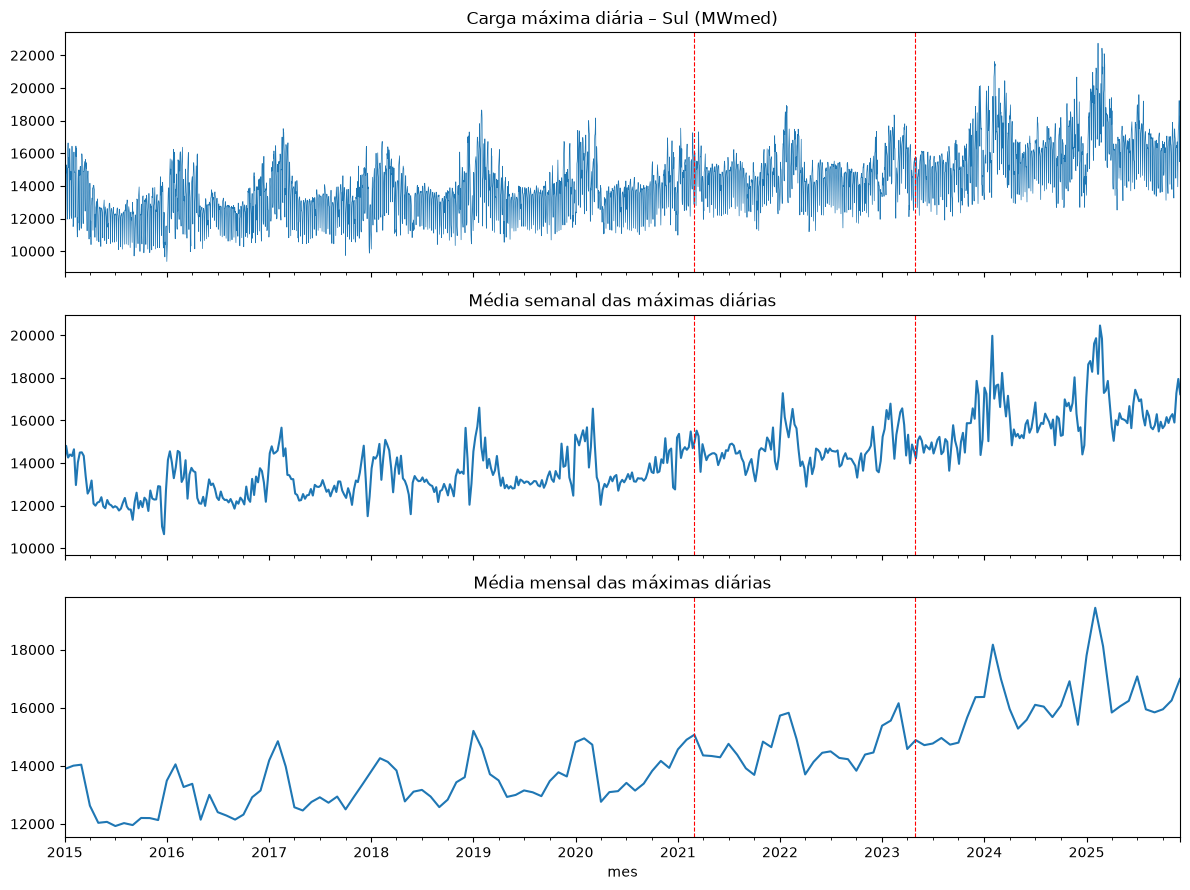

In [15]:
fig, axes = plt.subplots(3, 1, figsize=(12, 9), sharex=True)
base_diaria["carga_max"].plot(ax=axes[0], lw=0.5, title="Carga máxima diária – Sul (MWmed)")
base_semanal["carga_max_media"].plot(ax=axes[1], title="Média semanal das máximas diárias")
base_mensal["carga_max_media"].plot(ax=axes[2], title="Média mensal das máximas diárias")
for ax in axes:
    for d, _ in REGIMES_ONS:
        ax.axvline(pd.Timestamp(d), color="red", ls="--", lw=0.8)
plt.tight_layout()

> **Interpretação**
>
> A carga máxima diária cresce de forma contínua: a média anual passou de cerca de 12,6 GW em 2015 para 16,8 GW em 2025 (+33%), e o maior pico passou de 16,6 GW para 22,7 GW. Parte do aumento nas linhas vermelhas vem da mudança de metodologia do ONS, e não só do maior consumo. Isso vale principalmente para 29/04/2023, quando o ONS passou a somar a geração distribuída estimada. A média sobe a cada regime (13,3 → 14,6 → 16,1 GW).
>
> Há um padrão anual claro: a carga é maior no verão (fevereiro é o mês mais alto, com 15,5 GW em média) e menor entre abril e outubro (cerca de 13,7 GW). Fins de semana ficam cerca de 14% abaixo dos dias úteis. Na série diária aparecem quedas pontuais (feriados, início da pandemia em 2020) e picos em ondas de calor. Os maiores valores da série são de fev–mar/2025, com máximas acima de 31 °C. Esses dias foram mantidos. Nas visões semanal e mensal o ruído do dia a dia some e ficam visíveis a tendência e a sazonalidade.

## 9. Validação cruzada com outros datasets do ONS

1. A média diária calculada aqui, comparada com a **Carga de Energia Diária**.
2. A média mensal, comparada com a **Carga de Energia Mensal**.
3. A máxima diária (o máximo das médias horárias), comparada com a **Demanda Máxima Diária** (2024–2025), que traz o pico instantâneo e o integralizado.

In [16]:
diaria_ons = ler_ons("carga_energia_diaria", "val_cargaenergiamwmed")
diaria_ons = diaria_ons.set_index(diaria_ons["din_instante"].dt.normalize())["val_cargaenergiamwmed"].loc[INICIO:FIM]
cmp_d = pd.DataFrame({"calculada": base_diaria["carga_media"], "ons_diaria": diaria_ons}).dropna()
cmp_d["dif_pct"] = 100 * (cmp_d["calculada"] - cmp_d["ons_diaria"]) / cmp_d["ons_diaria"]
resumo_d = cmp_d.groupby(cmp_d.index.year)["dif_pct"].agg(["mean", "std", "min", "max"]).round(2)
resumo_d

,mean,std,min,max
2015,-0.0,0.00,-0.00,0.00
2016,-0.0,0.00,-0.00,0.00
2017,-0.0,0.01,-0.12,0.05
2018,0.0,0.00,-0.00,0.01
2019,-0.0,0.00,-0.00,0.00
2020,-0.0,0.00,-0.00,0.00
2021,-0.0,0.00,-0.00,0.00
2022,-0.0,0.00,-0.00,0.00
2023,-0.0,0.00,-0.00,0.00
2024,-0.0,0.00,-0.00,0.00


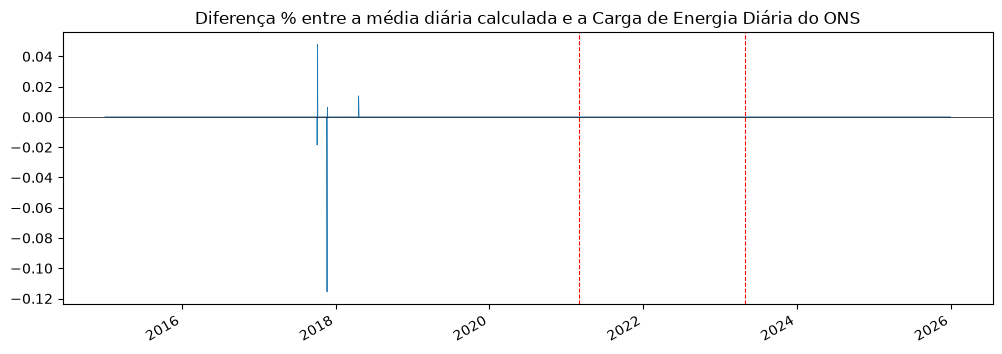

In [17]:
ax = cmp_d["dif_pct"].plot(lw=0.6, title="Diferença % entre a média diária calculada e a Carga de Energia Diária do ONS")
for d, _ in REGIMES_ONS:
    ax.axvline(pd.Timestamp(d), color="red", ls="--", lw=0.8)
ax.axhline(0, color="k", lw=0.5);

In [18]:
mensal_ons = ler_ons("carga_energia_mensal", "val_cargaenergiamwmed")
mensal_ons = mensal_ons.set_index(mensal_ons["din_instante"].dt.to_period("M").dt.to_timestamp())["val_cargaenergiamwmed"]
cmp_m = pd.DataFrame({"calculada": base_mensal["carga_media"], "ons_mensal": mensal_ons}).dropna()
cmp_m["dif_pct"] = 100 * (cmp_m["calculada"] - cmp_m["ons_mensal"]) / cmp_m["ons_mensal"]
cmp_m.groupby(cmp_m.index.year)["dif_pct"].agg(["mean", "min", "max"]).round(2)

,mean,min,max
2015,-4.69,-7.36,-2.94
2016,-2.69,-4.77,-1.22
2017,-2.80,-4.53,-1.34
2018,-3.02,-4.38,-2.04
2019,-2.89,-4.41,-1.71
2020,-3.27,-6.19,-1.35
2021,-1.24,-3.90,1.49
2022,-3.21,-5.41,-0.29
2023,-1.48,-3.85,1.37
2024,-1.01,-3.25,1.65


In [19]:
dem = pd.concat(pd.read_parquet(f) for f in sorted((DIR_RAW / "demanda_maxima_diaria").glob("*.parquet")))
dem = dem[dem["id_subsistema"].str.strip() == SUBSISTEMA].set_index("dat_referencia").sort_index()
cmp_dem = base_diaria[["carga_max", "hora_pico"]].join(
    dem[["val_demandaintegralizada", "val_demandainstantanea", "din_demandainstantanea"]], how="inner")
cmp_dem["inst_sobre_max_pct"] = 100 * (cmp_dem["val_demandainstantanea"] / cmp_dem["carga_max"] - 1)
cmp_dem["integ_sobre_max_pct"] = 100 * (cmp_dem["val_demandaintegralizada"] / cmp_dem["carga_max"] - 1)
cmp_dem["mesma_hora_pico"] = cmp_dem["din_demandainstantanea"].dt.hour == cmp_dem["hora_pico"]
cmp_dem[["inst_sobre_max_pct", "integ_sobre_max_pct", "mesma_hora_pico"]].describe().round(2)

,inst_sobre_max_pct,integ_sobre_max_pct
count,731.00,731.00
mean,1.48,-0.26
std,1.07,0.54
min,-10.18,-11.71
25%,0.90,-0.42
50%,1.36,-0.21
75%,1.93,0.00
max,10.53,0.73


> **Interpretação**
>
> 1. A média diária calculada aqui é igual à Carga de Energia Diária oficial (diferença de 0,00%). Isso confirma que a leitura e a agregação dos dados horários estão corretas.
> 2. A Carga de Energia Mensal oficial fica 1% a 5% acima da média calculada (até 8% em alguns meses). Como o valor diário bate exatamente, a diferença vem da forma como o ONS monta o dataset mensal, e não de erro no tratamento. Por isso o dataset mensal não é usado como referência.
> 3. A carga máxima diária fica muito próxima da demanda máxima integralizada (mediana de −0,2%) e cerca de 1,4% abaixo do pico instantâneo, o que é esperado: a média de uma hora suaviza os picos de poucos minutos. O alvo do projeto representa bem o pico do dia.

## 10. Benchmark do ONS (tabela separada, nunca usada como atributo)

- **Carga de Energia Programada:** carga global programada na véspera, em base semi-horária. O instante é o fim do intervalo, em UTC. Para comparar com a série horária, converte-se para a hora local, tira-se a média de cada hora e depois o máximo diário. Disponível a partir de 05/03/2021.
- **Valores da Programação Diária:** o dataset traz a **geração** programada por usina (`val_geracaoprogramada`, `nom_usina`, `tip_geracao`), não a carga. Por isso **não é usado** como benchmark de carga.

In [20]:
prog = pd.concat(pd.read_csv(f, sep=";") for f in sorted((DIR_RAW / "carga_energia_programada").glob(f"CARGA_PROGRAMADA_{SUBSISTEMA}_*.csv")))
fim_intervalo = pd.to_datetime(prog["din_referenciautc"], utc=True)
prog["instante"] = (fim_intervalo - pd.Timedelta(minutes=30)).dt.tz_convert(FUSO).dt.tz_localize(None).dt.floor("h")
prog_h = prog.groupby("instante")["val_cargaglobalprogramada"].mean()
prog_h = prog_h.loc[INICIO:f"{FIM} 23:00"]
benchmark_ons = pd.DataFrame({
    "carga_max_programada": prog_h.groupby(prog_h.index.normalize()).max(),
    "carga_media_programada": prog_h.groupby(prog_h.index.normalize()).mean(),
    "n_horas_programadas": prog_h.groupby(prog_h.index.normalize()).count(),
})
benchmark_ons.index.name = "data"
cmp_b = benchmark_ons.join(base_diaria["carga_max"]).dropna()
err = cmp_b["carga_max_programada"] - cmp_b["carga_max"]
print(f"dias: {len(cmp_b)} | MAE: {err.abs().mean():.1f} MWmed | MAPE: {100 * (err.abs() / cmp_b['carga_max']).mean():.2f}%")
benchmark_ons.head()

dias: 1762 | MAE: 469.4 MWmed | MAPE: 3.04%


,carga_max_programada,carga_media_programada,n_horas_programadas
data,,,
2021-03-05,15614.4915,13742.890448,24
2021-03-06,12670.4145,10654.258177,24
2021-03-07,12684.9205,10011.241083,24
2021-03-08,15061.2235,12930.478906,24
2021-03-09,15560.0770,13698.013094,24


In [21]:
pd.read_parquet(sorted((DIR_RAW / "programacao_diaria").glob("*.parquet"))[0]).columns.tolist()

['din_programacaodia',
 'num_patamar',
 'cod_exibicaousina',
 'nom_usina',
 'tip_geracao',
 'nom_modalidadeoperacao',
 'id_subsistema',
 'nom_subsistema',
 'id_estado',
 'nom_estado',
 'val_geracaoprogramada',
 'val_disponibilidade',
 'val_ordemmerito',
 'val_inflexibilidade',
 'val_uc',
 'val_razaoeletrica',
 'val_geracaoenergetica',
 'val_gesubgsub',
 'val_exportacao',
 'val_reposicaoexportacao',
 'val_faltacombustivel']

> **Interpretação**
>
> A previsão que o próprio ONS faz na véspera erra a carga máxima do dia, em média, em cerca de 469 MWmed (3,0%), considerando 1.762 dias desde mar/2021. Esse é o nível de erro de uma previsão profissional e serve de referência para os modelos da etapa 4. Essa tabela só serve para comparação e não entra como atributo dos modelos.

## 11. Checagens finais e exportação

In [22]:
assert base_diaria.index.is_unique and len(base_diaria) == len(dias)
assert base_diaria.index.min() == pd.Timestamp(INICIO) and base_diaria.index.max() == pd.Timestamp(FIM)
ok = base_diaria.dropna(subset=["carga_max"])
assert (ok["carga_max"] >= ok["carga_media"]).all() and (ok["carga_media"] >= ok["carga_min"]).all()
assert base_diaria[["tmax", "tmin", "tmed", "chuva_mm"]].notna().all().all(), "clima com lacunas"
assert (base_diaria.groupby("ano")["feriado_nacional"].sum() >= 12).all()
print("dias sem carga_max:", base_diaria["carga_max"].isna().sum())

DIR_OUT.mkdir(exist_ok=True)
saidas = {
    "base_horaria": base_horaria.set_index("instante"),
    "base_diaria": base_diaria,
    "base_semanal": base_semanal,
    "base_mensal": base_mensal,
    "benchmark_ons": benchmark_ons,
}
for nome, df in saidas.items():
    df.to_parquet(DIR_OUT / f"{nome}.parquet")
    print(f"{nome:14s} {df.shape}  ->  {DIR_OUT / (nome + '.parquet')}")

dias sem carga_max: 1
base_horaria   (96432, 12)  ->  processado/base_horaria.parquet
base_diaria    (4018, 35)  ->  processado/base_diaria.parquet
base_semanal   (575, 20)  ->  processado/base_semanal.parquet
base_mensal    (132, 20)  ->  processado/base_mensal.parquet
benchmark_ons  (1762, 3)  ->  processado/benchmark_ons.parquet


In [23]:
base_diaria.dtypes.to_frame("dtype").T

,carga_max,carga_media,carga_min,n_horas_obs,n_horas_reais,n_horas_imputadas,n_horas_suspeitas,hora_pico,dia_incompleto,tmax,tmin,tmed,tmax_aparente,umidade_med,chuva_mm,cdd,hdd,tmax_curitiba,tmax_florianopolis,tmax_porto_alegre,feriado_nacional,frac_pop_feriado_estadual,nome_feriado,feriado,vespera_feriado,pos_feriado,ponte,ano,mes,dia_semana,fim_de_semana,dia_ano,semana_iso,regime_ons,pandemia
dtype,float64,float64,float64,int64,int64,int64,int64,float64,bool,float64,float64,float64,float64,float64,float64,float64,float64,float64,float64,float64,bool,float64,string,bool,bool,bool,bool,int32,int32,int32,bool,int32,int64,int64,bool
